# How much work does it take to multiply two tables of numbers?

The companion notebook to `notes.pdf`. You multiply two small tables by hand and count, then make the numbers
count their own multiplications, check Strassen's seven products for every possible input, watch the saving
compound on blocks inside blocks, run the polynomial trick behind the nine-fourths upper bound, compute the
claimed floor exactly, and plot the record staircase from 1969 to 2026.

Everything here is counted, nothing is timed: a count is the same on every machine. The rule is the one the
papers use: a multiplication of two values that both depend on the input tables costs one; adding, subtracting,
and multiplying or dividing by a fixed number cost nothing.

Standard library only (matplotlib is optional, for two plots whose numbers are also printed). It runs in a couple
of seconds. Set `FULL = True` for the notes' sizes: Strassen run for real up to 128 rows and
polynomials up to 100 coefficients, about ten seconds more.

In [1]:
FULL = False                      # True: the notes' sizes (about 10 s more)
N_RUN = 128 if FULL else 32       # Strassen and the school way run for real up to this many rows
K_POLY = 100 if FULL else 10      # the polynomial trick up to this many coefficients

import math
import random
from fractions import Fraction

try:
    import matplotlib.pyplot as plt
except ImportError:               # the two plots are optional; their numbers are printed too
    plt = None

PEOPLE, ITEMS, CITIES = ["Emma", "Liam"], ["coffee", "tea"], ["Austin", "Lima"]
ORDERS = [[2, 1], [1, 3]]         # Emma, Liam  x  coffee, tea
PRICES = [[5, 3], [4, 2]]         # coffee, tea x  Austin, Lima (dollars)

## 1. The café bill by hand

Emma orders 2 coffees and 1 tea,
Liam 1 coffee and 3 teas. A coffee costs
5 dollars in Austin and 3 in Lima, a tea
4 and 2. Each entry of the answer is one row of orders against one
column of prices. The three loops are the three sides of the "cube of products": person `i`, city `j`, item `k`.
Every line below is one small cube. Our run: 8 multiplications, the answer
`[[14, 8], [17, 9]]`.

In [2]:
answer = [[0, 0], [0, 0]]
count = 0
for i in range(2):                # person
    for j in range(2):            # city
        for k in range(2):        # item
            product = ORDERS[i][k] * PRICES[k][j]
            answer[i][j] += product
            count += 1
            print(f"cube ({i},{j},{k}): {PEOPLE[i]:<5} in {CITIES[j]:<6} {ITEMS[k]:<6} "
                  f"{ORDERS[i][k]} x {PRICES[k][j]} = {product}")
print("\nanswer:", answer, "  multiplications:", count)

cube (0,0,0): Emma  in Austin coffee 2 x 5 = 10
cube (0,0,1): Emma  in Austin tea    1 x 4 = 4
cube (0,1,0): Emma  in Lima   coffee 2 x 3 = 6
cube (0,1,1): Emma  in Lima   tea    1 x 2 = 2
cube (1,0,0): Liam  in Austin coffee 1 x 5 = 5
cube (1,0,1): Liam  in Austin tea    3 x 4 = 12
cube (1,1,0): Liam  in Lima   coffee 1 x 3 = 3
cube (1,1,1): Liam  in Lima   tea    3 x 2 = 6

answer: [[14, 8], [17, 9]]   multiplications: 8


## 2. Numbers that count their own multiplications

The `count += 1` above is a line somebody had to remember. A `Tracked` number carries its value and a shared tally,
and Python calls its `__mul__` for every `*` it evaluates, so the count comes from the arithmetic itself. A product
of two `Tracked` numbers counts; a `Tracked` number times a plain number (a fixed number) is free, and so is
adding. Run any recipe on `Tracked` numbers and read the tally afterwards.

In [3]:
class Tally:
    def __init__(self):
        self.n = 0


def _v(x):
    return x.v if isinstance(x, Tracked) else x


class Tracked:
    """A number that depends on the inputs: only input x input products are counted."""
    __slots__ = ("v", "t")

    def __init__(self, v, t):
        self.v, self.t = v, t

    def __add__(self, o):
        return Tracked(self.v + _v(o), self.t)
    __radd__ = __add__

    def __sub__(self, o):
        return Tracked(self.v - _v(o), self.t)

    def __rsub__(self, o):
        return Tracked(o - self.v, self.t)

    def __mul__(self, o):
        if isinstance(o, Tracked):           # input times input: the one that costs
            self.t.n += 1
            return Tracked(self.v * o.v, self.t)
        return Tracked(self.v * o, self.t)   # times a fixed number: free
    __rmul__ = __mul__

    def __truediv__(self, o):                # by a fixed number: free and exact
        if isinstance(o, Tracked):
            self.t.n += 1
            return Tracked(Fraction(self.v) / o.v, self.t)
        return Tracked(Fraction(self.v) / o, self.t)

    def __eq__(self, o):
        return self.v == _v(o)
    __hash__ = None

    def __repr__(self):
        return repr(self.v)


def track(M, t):
    return [[Tracked(x, t) for x in row] for row in M]


def plain(M):
    return [[_v(x) for x in row] for row in M]


def school(A, B):
    """Three loops: n x n tables take n * n * n multiplications."""
    n, m, p = len(A), len(B), len(B[0])
    return [[sum(A[i][k] * B[k][j] for k in range(m)) for j in range(p)] for i in range(n)]


t = Tally()
print("the school way:", plain(school(track(ORDERS, t), track(PRICES, t))), " multiplications:", t.n)
x, y = Tracked(3, t), Tracked(4, t)
t.n = 0
z = 2 * x + 5 * y - x / 2                    # fixed numbers only: free
print("2x + 5y - x/2 =", z, " multiplications counted:", t.n)
z = x * y                                    # input times input
print("x * y =", z, " multiplications counted:", t.n)

the school way: [[14, 8], [17, 9]]  multiplications: 8
2x + 5y - x/2 = Fraction(49, 2)  multiplications counted: 0
x * y = 12  multiplications counted: 1


## 3. Strassen's seven products, checked

Strassen (1969) builds seven products from sums and differences of the entries, then only adds and subtracts.
On the café tables our run gives the products 35, 20, 2, -3, 6, -8, -12 and the same answer as the
school way, from 7 multiplications.

In [4]:
def strassen2(A, B):
    (a11, a12), (a21, a22) = A
    (b11, b12), (b21, b22) = B
    m = [(a11 + a22) * (b11 + b22), (a21 + a22) * b11, a11 * (b12 - b22), a22 * (b21 - b11),
         (a11 + a12) * b22, (a21 - a11) * (b11 + b12), (a12 - a22) * (b21 + b22)]
    m1, m2, m3, m4, m5, m6, m7 = m
    return m, [[m1 + m4 - m5 + m7, m3 + m5], [m2 + m4, m1 - m2 + m3 + m6]]


t = Tally()
m, got = strassen2(track(ORDERS, t), track(PRICES, t))
print("m1..m7 =", m)
print("Strassen:", plain(got), " multiplications:", t.n, "  same as the school way:", plain(got) == plain(school(ORDERS, PRICES)))

m1..m7 = [35, 20, 2, -3, 6, -8, -12]
Strassen: [[14, 8], [17, 9]]  multiplications: 7   same as the school way: True


One example proves little. To check the recipe for **every** input, run it on letters instead of numbers. A
polynomial below is a dict from a word of letters (kept in the order they were multiplied, so `a11*b11` and
`b11*a11` are different words) to its coefficient. If the seven products, added up, give exactly the school
way's sums, with every `a` still on the left of its `b`, the recipe never used $ab = ba$, and so it works when
the entries are blocks, whose products depend on the order.

In [5]:
class Poly(dict):
    """Sums of words of letters, multiplied in order (no ab = ba)."""

    @staticmethod
    def var(name):
        return Poly({(name,): 1})

    def __add__(self, o):
        out = Poly(self)
        for w, c in o.items():
            out[w] = out.get(w, 0) + c
        return Poly({w: c for w, c in out.items() if c})

    def __neg__(self):
        return Poly({w: -c for w, c in self.items()})

    def __sub__(self, o):
        return self + (-o)

    def __mul__(self, o):
        out = Poly()
        for w1, c1 in self.items():
            for w2, c2 in o.items():
                out[w1 + w2] = out.get(w1 + w2, 0) + c1 * c2
        return Poly({w: c for w, c in out.items() if c})

    def __repr__(self):
        return " + ".join(("" if c == 1 else f"{c}*") + "*".join(w) for w, c in sorted(self.items())) or "0"


A = [[Poly.var("a11"), Poly.var("a12")], [Poly.var("a21"), Poly.var("a22")]]
B = [[Poly.var("b11"), Poly.var("b12")], [Poly.var("b21"), Poly.var("b22")]]
m, got = strassen2(A, B)
want = [[A[i][0] * B[0][j] + A[i][1] * B[1][j] for j in range(2)] for i in range(2)]   # the school way, by hand
print("m1 =", m[0])
print("m1 + m4 - m5 + m7 =", got[0][0], "\n")
for i in range(2):
    for j in range(2):
        print(f"c{i + 1}{j + 1}: {str(got[i][j]):<22} school way: {str(want[i][j]):<22} equal: {got[i][j] == want[i][j]}")

m1 = a11*b11 + a11*b22 + a22*b11 + a22*b22
m1 + m4 - m5 + m7 = a11*b11 + a12*b21 

c11: a11*b11 + a12*b21      school way: a11*b11 + a12*b21      equal: True
c12: a11*b12 + a12*b22      school way: a11*b12 + a12*b22      equal: True
c21: a21*b11 + a22*b21      school way: a21*b11 + a22*b21      equal: True
c22: a21*b12 + a22*b22      school way: a21*b12 + a22*b22      equal: True


## 4. Blocks inside blocks: the saving compounds

The same recipe with blocks in place of numbers: cut each table into four quarter blocks, make seven block
products (each done the same way, inside), and add. For $n = 2^k$ rows the school way takes $8^k = n^3$
multiplications and Strassen's $7^k$. Our run counted every one up to 128 rows on random
whole numbers and checked the answers agree; at 128 rows the counts were
2,097,152 and 823,543. The formulas give 1,073,741,824
and 282,475,249 at 1,024. The quick default runs up to 32 rows.

In [6]:
def add(X, Y, s=1):
    return [[a + b if s == 1 else a - b for a, b in zip(r, q)] for r, q in zip(X, Y)]


def split(X):
    h = len(X) // 2
    return [[[r[:h] for r in X[:h]], [r[h:] for r in X[:h]]], [[r[:h] for r in X[h:]], [r[h:] for r in X[h:]]]]


def strassen(A, B, calls=None):
    """Strassen on blocks down to single numbers; calls[size] counts the block products of each size."""
    n = len(A)
    if calls is not None:
        calls[n] = calls.get(n, 0) + 1
    if n == 1:
        return [[A[0][0] * B[0][0]]]
    (a11, a12), (a21, a22) = split(A)
    (b11, b12), (b21, b22) = split(B)
    m1 = strassen(add(a11, a22), add(b11, b22), calls)
    m2 = strassen(add(a21, a22), b11, calls)
    m3 = strassen(a11, add(b12, b22, -1), calls)
    m4 = strassen(a22, add(b21, b11, -1), calls)
    m5 = strassen(add(a11, a12), b22, calls)
    m6 = strassen(add(a21, a11, -1), add(b11, b12), calls)
    m7 = strassen(add(a12, a22, -1), add(b21, b22), calls)
    c11, c12 = add(add(m1, m4), add(m7, m5, -1)), add(m3, m5)
    c21, c22 = add(m2, m4), add(add(m1, m2, -1), add(m3, m6))
    return [r1 + r2 for r1, r2 in zip(c11, c12)] + [r1 + r2 for r1, r2 in zip(c21, c22)]


rng = random.Random(20261125)                 # the notes' seed
rows = []
print(f"{'n':>6} {'school, n^3':>15} {'Strassen, 7^k':>15} {'ratio':>8}")
for k in range(1, 11):
    n = 2 ** k
    if n <= 128:
        A = [[rng.randint(-9, 9) for _ in range(n)] for _ in range(n)]
        B = [[rng.randint(-9, 9) for _ in range(n)] for _ in range(n)]
    if n <= N_RUN:
        t1, t2 = Tally(), Tally()
        assert plain(school(track(A, t1), track(B, t1))) == plain(strassen(track(A, t2), track(B, t2)))
        s, st, how = t1.n, t2.n, "run and counted"
    else:
        s, st, how = n ** 3, 7 ** k, "formula"
    rows.append((n, s, st))
    print(f"{n:>6,} {s:>15,} {st:>15,} {st / s:>8.4f}  {how}")

calls = {}
strassen([[1] * 16] * 16, [[1] * 16] * 16, calls)
print("\ninside one 16 x 16 product:", ", ".join(f"{c:,} of size {sz}" for sz, c in sorted(calls.items(), reverse=True)))

     n     school, n^3   Strassen, 7^k    ratio
     2               8               7   0.8750  run and counted
     4              64              49   0.7656  run and counted
     8             512             343   0.6699  run and counted
    16           4,096           2,401   0.5862  run and counted
    32          32,768          16,807   0.5129  run and counted
    64         262,144         117,649   0.4488  formula
   128       2,097,152         823,543   0.3927  formula
   256      16,777,216       5,764,801   0.3436  formula
   512     134,217,728      40,353,607   0.3007  formula
 1,024   1,073,741,824     282,475,249   0.2631  formula

inside one 16 x 16 product: 1 of size 16, 7 of size 8, 49 of size 4, 343 of size 2, 2,401 of size 1


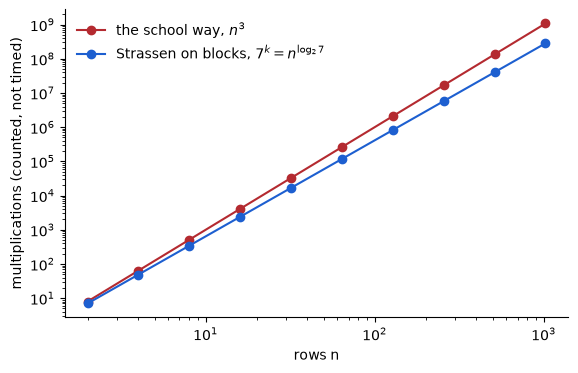

In [7]:
if plt:
    ns = [r[0] for r in rows]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.loglog(ns, [r[1] for r in rows], "o-", color="#B42A30", label="the school way, $n^3$")
    ax.loglog(ns, [r[2] for r in rows], "o-", color="#1D5FD0", label=r"Strassen on blocks, $7^k = n^{\log_2 7}$")
    ax.set_xlabel("rows n"), ax.set_ylabel("multiplications (counted, not timed)")
    ax.legend(frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.show()

## 5. From a recipe to a power

A recipe that multiplies $v \times v$ blocks with $r$ block products, used inside itself, costs $r^k$
multiplications for $n = v^k$: that is $n^{\log_v r}$. Each doubling of $n$ multiplies the count by
$2^{\text{power}}$. Our run: $\log_2 7 = 2.807355$, and $2^{9/4} = 4.75683$.

In [8]:
for name, v, r in (("the school way", 2, 8), ("Strassen", 2, 7), ("Strassen twice, as a 4 x 4 recipe", 4, 49)):
    print(f"{name:<34} v = {v}, r = {r:>2}: power log_v r = {math.log(r, v):.6f}")
print("\nwhen n doubles, the count is multiplied by 2^power:")
for name, w in (("n^3", 3), ("n^(log2 7)", math.log2(7)), ("n^(9/4)", 9 / 4), ("n^2", 2)):
    print(f"  {name:<11} x {2 ** w:.5f}")

the school way                     v = 2, r =  8: power log_v r = 3.000000
Strassen                           v = 2, r =  7: power log_v r = 2.807355
Strassen twice, as a 4 x 4 recipe  v = 4, r = 49: power log_v r = 2.807355

when n doubles, the count is multiplied by 2^power:
  n^3         x 8.00000
  n^(log2 7)  x 7.00000
  n^(9/4)     x 4.75683
  n^2         x 4.00000


## 6. The three-point polynomial trick

$(3 + 2x)(5 + 4x)$ the school way multiplies every pair:
4 products. The answer has three coefficients, and three values pin it down, so put in
$x = -1, 0, 1$, multiply the values (our run:
1, 15, 45), and rebuild with additions and divisions by fixed numbers:
3 products, the same $15 + 22x + 8x^2$.
The rebuild is Lagrange interpolation with exact fractions.

In [9]:
def poly_school(a, b):
    out = [0] * (len(a) + len(b) - 1)
    for i in range(len(a)):
        for j in range(len(b)):
            out[i + j] = a[i] * b[j] + out[i + j]
    return out


def poly_points(a, b):
    k = len(a) + len(b) - 1
    xs = [Fraction(x) for x in range(-(k // 2), k - k // 2)]      # 3 points: -1, 0, 1
    value = lambda p, x: sum((q * x ** i for i, q in enumerate(p)), Fraction(0))
    vals = [value(a, x) * value(b, x) for x in xs]                 # the only products that count
    coef = [Fraction(0)] * k
    for i, xi in enumerate(xs):                                    # Lagrange: fixed numbers times the values
        basis, den = [Fraction(1)], Fraction(1)
        for j, xj in enumerate(xs):
            if j != i:
                basis = [(basis[s - 1] if s else 0) - xj * (basis[s] if s < len(basis) else 0)
                         for s in range(len(basis) + 1)]
                den *= xi - xj
        for s, q in enumerate(basis):
            coef[s] = vals[i] * (q / den) + coef[s]
    return [int(_v(c)) for c in coef], xs, vals


t = Tally()
a, b = [Tracked(3, t), Tracked(2, t)], [Tracked(5, t), Tracked(4, t)]
print("school way:", [_v(c) for c in poly_school(a, b)], " products:", t.n)
t.n = 0
coeffs, xs, vals = poly_points(a, b)
print("points", [int(x) for x in xs], "values", [int(_v(v)) for v in vals], "rebuilt:", coeffs, " products:", t.n)

rng = random.Random(7)
print(f"\n{'k coefficients':>15} {'school, k^2':>12} {'points, 2k-1':>13}")
for k in (2, 3, 5, 10, 100):
    p, q = [rng.randint(1, 9) for _ in range(k)], [rng.randint(1, 9) for _ in range(k)]
    if k > K_POLY:
        continue
    t1, t2 = Tally(), Tally()
    ref = [_v(c) for c in poly_school([Tracked(x, t1) for x in p], [Tracked(x, t1) for x in q])]
    assert poly_points([Tracked(x, t2) for x in p], [Tracked(x, t2) for x in q])[0] == ref
    print(f"{k:>15,} {t1.n:>12,} {t2.n:>13,}")

school way: [15, 22, 8]  products: 4
points [-1, 0, 1] values [1, 15, 45] rebuilt: [15, 22, 8]  products: 3

 k coefficients  school, k^2  points, 2k-1
              2            4             3
              3            9             5
              5           25             9
             10          100            19


## 7. Packing: closing in on 9/4

Rafael Pass's explicit proof of the upper bound packs matrix products into polynomial products; a packing of size
$c$ reaches "any exponent strictly above 3/2 · log(1 + 3/(c − 1)) / log(1 + 2/c). This threshold tends to 9/4 as c → ∞". We only evaluate his formula. Our run:
2.564267 at $c = 4$, 2.251125 at
$c = 1,000$.

In [10]:
for c in (2, 3, 4, 10, 100, 1000, 10 ** 6):
    print(f"c = {c:>9,}: {1.5 * math.log(1 + 3 / (c - 1)) / math.log(1 + 2 / c):.6f}")
print("limit: 3/2 * 3/2 =", 9 / 4)

c =         2: 3.000000
c =         3: 2.690617
c =         4: 2.564267
c =        10: 2.366824
c =       100: 2.261288
c =     1,000: 2.251125
c = 1,000,000: 2.250001
limit: 3/2 * 3/2 = 2.25


## 8. The claimed floor, exactly

OpenAI's paper of November 24, 2026 claims that any circuit needs at least $\lceil n^{9/4}/2 \rceil$
multiplications or divisions, even if additions are free. Floating point would round, so this computes the floor
with whole numbers only: the least $m$ with $(2m)^4 \ge n^9$. Our run: 500,000,000 at
$n = 10,000$, where the answer has 100,000,000 numbers and the extra
factor $n^{1/4}$ is 10. A claim, as of 2026-11-25: this checks the
arithmetic of the bound, not its proof.

In [11]:
def floor_bound(n):
    r = math.isqrt(math.isqrt(n ** 9))       # floor of the 4th root of n^9
    if r ** 4 < n ** 9:
        r += 1                               # ceiling of n^(9/4)
    return (r + 1) // 2                      # least m with 2m >= n^(9/4)


print(f"{'n':>12} {'answer, n^2':>20} {'claimed floor':>22} {'floor / n^2':>12} {'n^(1/4)':>9}")
for n in (2, 4, 10, 100, 1000, 10_000, 100_000, 10 ** 8):
    print(f"{n:>12,} {n * n:>20,} {floor_bound(n):>22,} {floor_bound(n) / n ** 2:>12.3f} {n ** 0.25:>9.6g}")

           n          answer, n^2          claimed floor  floor / n^2   n^(1/4)
           2                    4                      3        0.750   1.18921
           4                   16                     12        0.750   1.41421
          10                  100                     89        0.890   1.77828
         100               10,000                 15,812        1.581   3.16228
       1,000            1,000,000              2,811,707        2.812   5.62341
      10,000          100,000,000            500,000,000        5.000        10
     100,000       10,000,000,000         88,913,970,502        8.891   17.7828
 100,000,000 10,000,000,000,000,000 500,000,000,000,000,000       50.000       100


## 9. The record staircase

Every published upper bound on $\omega$, from Wikipedia's history table (read 2026-11-25) and the
August 2026 record (arXiv:2608.16884): 16 records in
57 years, then OpenAI's 2026 steps to 9/4. From 1990 to
August 2026 the record moved 0.004323; the step to 9/4 is
0.121177 more.

1969  2.8074     Strassen
1978  2.796      Pan
1979  2.78       Bini, Capovani, Romani
1981  2.522      Schönhage
1981  2.517      Romani
1981  2.496      Coppersmith, Winograd
1986  2.479      Strassen
1990  2.3755     Coppersmith, Winograd
2010  2.3737     Stothers
2012  2.3729     Williams
2014  2.3728639  Le Gall
2020  2.3728596  Alman, Williams
2022  2.371866   Duan, Wu, Zhou
2024  2.371552   Williams, Xu, Xu, Zhou
2024  2.371339   Alman, Duan, Williams, Xu, Xu, Zhou
2026  2.371177   Dupont et al. (AlphaEvolve)
2026  9/4 = 2.25  OpenAI: upper bound Oct 2 (re-proved by others), matching lower bound claimed Nov 24


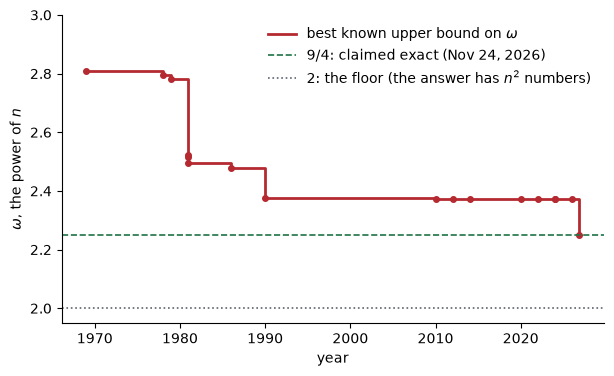

In [12]:
RECORDS = [(1969, 2.8074, "Strassen"), (1978, 2.796, "Pan"), (1979, 2.78, "Bini, Capovani, Romani"),
           (1981, 2.522, "Schönhage"), (1981, 2.517, "Romani"), (1981, 2.496, "Coppersmith, Winograd"),
           (1986, 2.479, "Strassen"), (1990, 2.3755, "Coppersmith, Winograd"), (2010, 2.3737, "Stothers"),
           (2012, 2.3729, "Williams"), (2014, 2.3728639, "Le Gall"), (2020, 2.3728596, "Alman, Williams"),
           (2022, 2.371866, "Duan, Wu, Zhou"), (2024, 2.371552, "Williams, Xu, Xu, Zhou"),
           (2024, 2.371339, "Alman, Duan, Williams, Xu, Xu, Zhou"), (2026, 2.371177, "Dupont et al. (AlphaEvolve)")]
for year, w, who in RECORDS:
    print(f"{year}  {w:<10} {who}")
print("2026  9/4 = 2.25  OpenAI: upper bound Oct 2 (re-proved by others), matching lower bound claimed Nov 24")

if plt:
    years = [r[0] for r in RECORDS] + [2026.9]
    bounds = [r[1] for r in RECORDS] + [2.25]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.step(years, bounds, where="post", color="#B42A30", lw=2, label="best known upper bound on $\\omega$")
    ax.plot(years, bounds, "o", color="#B42A30", ms=4)
    ax.axhline(2.25, color="#1E7346", ls="--", lw=1.2, label="9/4: claimed exact (Nov 24, 2026)")
    ax.axhline(2, color="#5C636E", ls=":", lw=1.2, label="2: the floor (the answer has $n^2$ numbers)")
    ax.set_xlabel("year"), ax.set_ylabel(r"$\omega$, the power of $n$"), ax.set_ylim(1.95, 3.0)
    ax.legend(frameon=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.show()

## Your turn

**1. Change the bill.** Put your own orders and prices into `ORDERS` and `PRICES` at the top (any whole numbers,
negative too) and rerun sections 1 and 3. Strassen's seven products still give the school way's answer: section 3
proved it for every input. Which entry changes if only the price of tea in Lima changes?

**2. Where to stop the recursion.** The count in the papers ignores additions, but Strassen's recipe pays
18 additions and
subtractions of blocks at every level, against the school way's 4 for a 2 × 2 product. The
cell below counts **all** the arithmetic (multiplications plus additions) for n = 1,024 when the recursion
stops at blocks of size `s` and finishes the school way. Change `n` and see where the best cut moves; it's a count,
so it's the same on every machine, and a real program also pays for moving numbers around, which no count shows.

In [13]:
def arithmetic(n, s):
    """Multiplications and additions for n x n: Strassen down to s x s blocks, then the school way."""
    if n <= s:
        return n ** 3, n * n * (n - 1)               # the school way: n^3 products, n^2 (n - 1) additions
    h = n // 2
    mul, add_ = arithmetic(h, s)
    return 7 * mul, 7 * add_ + 18 * h * h            # seven half-size products, 18 additions of h x h blocks


n = 1024
print(f"{'stop at s':>10} {'multiplications':>16} {'additions':>16} {'total':>16}")
for e in range(0, 11):
    s = 2 ** e
    mul, add_ = arithmetic(n, s)
    print(f"{s:>10,} {mul:>16,} {add_:>16,} {mul + add_:>16,}")

 stop at s  multiplications        additions            total
         1      282,475,249    1,688,560,038    1,971,035,287
         2      322,828,856    1,123,609,540    1,446,438,396
         4      368,947,264      823,839,888    1,192,787,152
         8      421,654,016      678,896,320    1,100,550,336
        16      481,890,304      626,189,568    1,108,079,872
        32      550,731,776      630,492,160    1,181,223,936
        64      629,407,744      672,288,768    1,301,696,512
       128      719,323,136      741,130,240    1,460,453,376
       256      822,083,584      831,848,448    1,653,932,032
       512      939,524,096      942,407,680    1,881,931,776
     1,024    1,073,741,824    1,072,693,248    2,146,435,072
